In [1]:
import os

# os.environ["HF_HOME"] = "/mnt/disks/ai-training/hf_cache"

import copy
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm

from lecture_utils import get_device, set_seed, load_stl10, STL10_CLASSES, BatchAugment, draw_self_distillation
from vision_transformer import Block, VisionTransformer, get_2d_sincos_pos_embed, resample_pos_embed
from self_distillation import ViTEncoder, ema_update, frozen_copy, cosine_momentum

%matplotlib inline
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", None)

In [2]:
DEVICE = get_device()
DATA_DIR = "../../data"
RESULTS_DIR = "results"      # small result tables of all training runs (part of the repo)
# The training runs of this lecture (13 runs, ViT-Ti/8 on STL-10) take ~4 GPU-hours on an RTX 5090, so they are
# NOT started from the notebook. Launch them from a terminal in this folder:
#     python experiments.py --list              # what will be run
#     python experiments.py --gpus 0            # run everything (finished runs are skipped)
# The notebook only reads the logs they write to `results/`. All other cells run in a few seconds.

set_seed(95431)
print(f"torch {torch.__version__} | timm {timm.__version__} | device: {DEVICE}")

torch 2.11.0+cu130 | timm 1.0.30 | device: cuda


# Agenda

1. [From BYOL to self-distillation](#Intro)
2. [DINO: the method](#DINO)
3. [DINO: what prevents collapse, and what the teacher and multi-crop give](#DINO_Experiments)
4. [What DINO features look like](#Features)
5. [From DINO to DINOv3](#DINO_Family)
    * [DINOv3 in detail](#DINOv3)
6. [I-JEPA: predicting representations of masked regions](#JEPA)
7. [DINO and I-JEPA under the same budget](#Comparison)
8. [Summary and self-check questions](#Summary)

# Resources

**DINO family**
- [DINO: Emerging Properties in Self-Supervised Vision Transformers (Caron et al., 2021)](https://arxiv.org/abs/2104.14294)
- [SwAV (multi-crop, prototypes, Sinkhorn–Knopp; Caron et al., 2020)](https://arxiv.org/abs/2006.09882)
- [iBOT: Image BERT Pre-Training with Online Tokenizer (Zhou et al., 2021)](https://arxiv.org/abs/2111.07832)
- [DINOv2: Learning Robust Visual Features without Supervision (Oquab et al., 2023)](https://arxiv.org/abs/2304.07193)
- [Vision Transformers Need Registers (Darcet et al., 2023)](https://arxiv.org/abs/2309.16588)
- [DINOv3 (Siméoni et al., 2025)](https://arxiv.org/abs/2508.10104)
- [SimDINO: Simplifying DINO via Coding Rate Regularization (Wu et al., 2025)](https://arxiv.org/abs/2502.10385)

**JEPA family**
- [A Path Towards Autonomous Machine Intelligence (the JEPA position paper; LeCun, 2022)](https://openreview.net/forum?id=BZ5a1r-kVsf)
- [I-JEPA: Self-Supervised Learning from Images with a Joint-Embedding Predictive Architecture (Assran et al., 2023)](https://arxiv.org/abs/2301.08243)
- [data2vec (Baevski et al., 2022)](https://arxiv.org/abs/2202.03555) and [MAE (He et al., 2021)](https://arxiv.org/abs/2111.06377)
- [V-JEPA (Bardes et al., 2024)](https://arxiv.org/abs/2404.08471) and [V-JEPA 2 (Assran et al., 2025)](https://arxiv.org/abs/2506.09985)
- [LeJEPA (Balestriero & LeCun, 2025)](https://arxiv.org/abs/2511.08544)

**Background**
- [Distilling the Knowledge in a Neural Network (Hinton et al., 2015)](https://arxiv.org/abs/1503.02531)
- [Mean teachers are better role models (Tarvainen & Valpola, 2017)](https://arxiv.org/abs/1703.01780)
- [A Cookbook of Self-Supervised Learning (Balestriero et al., 2023)](https://arxiv.org/abs/2304.12210)
- Code: [facebookresearch/dino](https://github.com/facebookresearch/dino), [facebookresearch/dinov2](https://github.com/facebookresearch/dinov2), [facebookresearch/dinov3](https://github.com/facebookresearch/dinov3), [facebookresearch/ijepa](https://github.com/facebookresearch/ijepa)

<a id='Intro'></a>
# From BYOL to self-distillation

**Knowledge distillation** (Hinton et al., 2015) trains a small *student* network to reproduce the output distribution of a large trained *teacher*. The student learns more from the teacher's soft probabilities ("70% cat, 25% lynx, 5% dog") than from a one-hot label.

In Lecture 4 we already met a teacher that needs no labels and no pre-training: the **momentum (target) network** of MoCo and BYOL, an exponential moving average (EMA) of the network being trained. **Self-distillation** takes this literally:

* the **student** is trained by gradient descent to match the output of the **teacher** on a different view of the same image;
* the **teacher** is the EMA of the student — an average of the student's own past weights, which is a better model than the student at any moment of training (the *mean teacher* effect);
* there are no negatives; what stops the pair from agreeing on a constant output is, again, an asymmetry between the two branches.

The two methods of this lecture are both built this way and differ in **what** is distilled:

| | **DINO** (2021) | **I-JEPA** (2023) |
|---|---|---|
| Views | several augmented crops of the image | one image, split into visible and hidden patches |
| The student sees | any crop, including small local ones | only the visible (context) patches |
| The teacher sees | large (global) crops | the whole image |
| The target | a probability distribution over $K$ prototypes, for the whole crop | the representation of every hidden patch |
| Against collapse | centering + sharpening of the teacher output | a predictor network + EMA target |
| What it learns to ignore | what the augmentations change (invariance) | nothing by design: it has to *predict*, not to be invariant |

DINO is the method behind the frozen backbones that topped the tables of Lecture 3 (DINOv2, DINOv3). I-JEPA is the first step of the JEPA programme: learning by prediction in representation space, without hand-crafted augmentations.

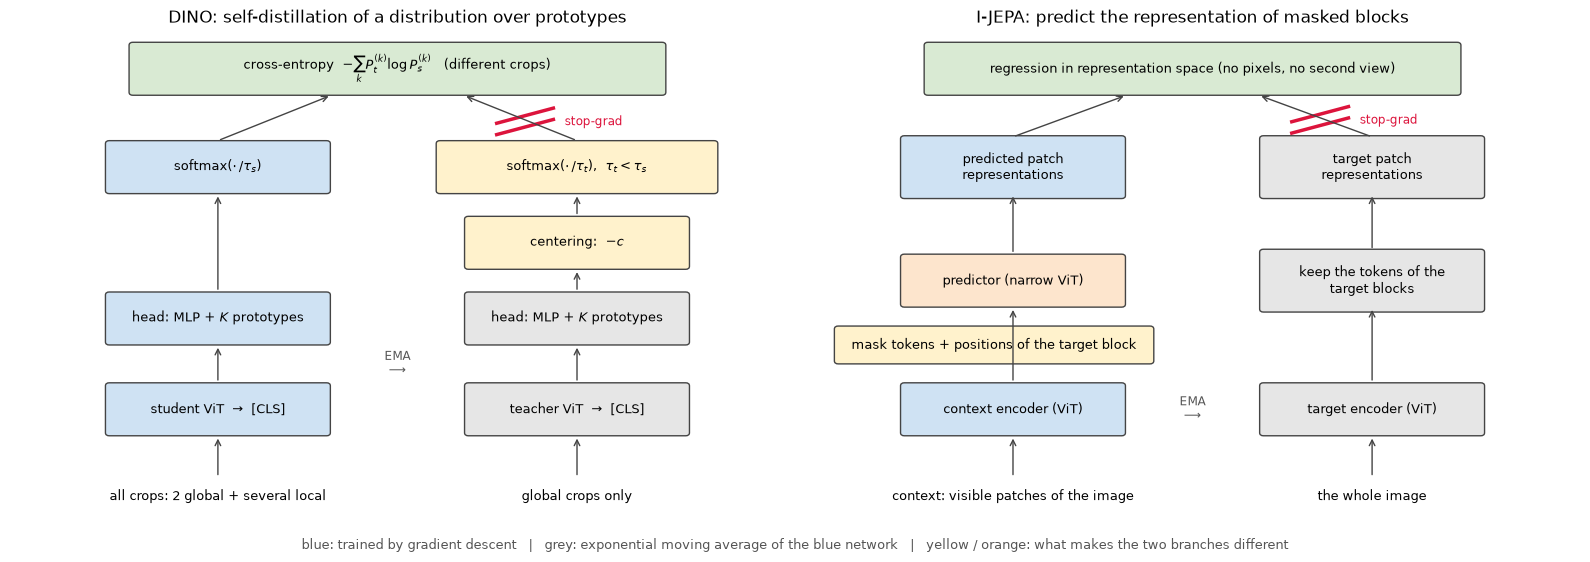

In [3]:
draw_self_distillation()
plt.show()

## Setup

Everything is the same as in Lecture 4, so the numbers of the two lectures can be compared directly:

* **Data**: the 100k unlabeled images of STL-10 ($96 \times 96$) for pre-training; the 5k labeled training images and the 8k test images only for evaluation.
* **Backbone**: the ViT of Lecture 1 as **ViT-Ti/8** — 12 blocks, width 192, $8 \times 8$ patches, so an image is $12 \times 12 = 144$ tokens; 5.4M parameters. (Lecture 4 used a ResNet-18 for most runs; self-distillation was designed for ViTs.)
* **Optimization**: AdamW, 10 epochs of warmup and cosine decay, batch 512, mixed precision. **100 epochs** for the two main runs, **30 epochs** for every ablation.
* **Evaluation** (Lecture 3 protocol, frozen backbone): weighted **k-NN** ($k = 20$) during training and an L-BFGS **linear probe** at the end, plus the effective rank (RankMe) of the features.

The code is in three files next to the notebook: `self_distillation.py` (everything implemented below), `train.py` (the training loop) and `experiments.py` (the list of runs). The cell below loads their results.

In [4]:
summary = pd.read_csv(os.path.join(RESULTS_DIR, "summary.csv")).set_index("name")


def load_run(name):
    """One row per epoch: loss, k-NN accuracy of the teacher (`knn_acc`) and of the student, effective rank."""
    return pd.read_csv(os.path.join(RESULTS_DIR, "runs", f"{name}.csv"))


def load_steps(name):
    """One row every 20 optimizer steps: loss and the diagnostics of the method."""
    return pd.read_csv(os.path.join(RESULTS_DIR, "runs", f"{name}_steps.csv"))


def plot_runs(runs, column, ax, title=None, ylabel=None, steps=False, **kwargs):
    """runs: {run name: label}. Plots a logged column against the epoch."""
    for name, label in runs.items():
        d = (load_steps(name) if steps else load_run(name)).dropna(subset=[column])
        ax.plot(d.epoch, d[column], label=label, **kwargs)
    ax.set_xlabel("epoch"); ax.set_ylabel(ylabel or column); ax.set_title(title or column)
    ax.grid(alpha=0.3); ax.legend(fontsize=8)


def results_table(runs, columns=("knn_acc", "linear_acc", "rankme_h")):
    """runs: {run name: label}. Final metrics of the runs as a styled table."""
    table = summary.loc[list(runs), list(columns)].rename(index=runs)
    table.index.name = None
    fmt = {c: "{:.1%}" for c in columns if "acc" in c}
    fmt.update({c: "{:.0f}" for c in columns if c.startswith("rankme") or c == "minutes"})
    fmt.update({c: "{:.2f}" for c in columns if c in ("std_h", "final_loss")})
    return table.style.format(fmt).background_gradient(subset=[c for c in columns if "acc" in c], cmap="Greens")


test_x, test_y = load_stl10(DATA_DIR, "test")
RANDOM_INIT_KNN = load_run("dino").iloc[0]["knn_acc"]       # epoch 0 of a run = randomly initialized ViT-Ti/8
print(f"{len(summary)} finished runs")
print(f"reference points (k-NN on frozen features): random-init ViT-Ti/8 {RANDOM_INIT_KNN:.1%} | "
      f"supervised ViT-Ti/8 on the 5k labeled images {summary.loc['supervised_5k', 'knn_acc']:.1%} | "
      f"MoCo v3 ViT-Ti/8 from Lecture 4 {summary.loc['mocov3_vit_tiny', 'knn_acc']:.1%}")

14 finished runs
reference points (k-NN on frozen features): random-init ViT-Ti/8 27.9% | supervised ViT-Ti/8 on the 5k labeled images 67.8% | MoCo v3 ViT-Ti/8 from Lecture 4 75.9%


<a id='DINO'></a>
# DINO: the method

**DINO** — self-**di**stillation with **no** labels (Caron et al., 2021) — is BYOL with three changes.

**1. The output is a distribution, not a vector.** On top of the backbone sits a head: an MLP, an L2-normalized bottleneck $z$, and a last layer of $K$ **prototypes** $w_1, \dots, w_K$ (65,536 in the paper, 4,096 here). The head outputs one number per prototype, the cosine similarity of the image to that prototype:

$$
g_{\theta}(x)^{(k)} = \frac{z^\top w_k}{\lVert z \rVert\, \lVert w_k \rVert} = \cos(z, w_k), \qquad z = \mathrm{MLP}(\mathrm{backbone}(x)) .
$$

In code this happens **inside the head**, not in the loss: `DINOHead.forward` normalizes $z$ and the prototypes and multiplies them. The paper implements the same thing as a weight-normalized linear layer applied to the normalized $z$. With the norm of each weight row fixed to 1 (the default), the layer computes exactly $\cos(z, w_k)$. The official code lets that norm be learned for small ViTs, which gives each prototype its own scale. `dino_loss` receives these $K$ values as "logits" and only turns them into a probability distribution with a temperature softmax:

$$
P_s(x)^{(k)} = \frac{\exp\big(g_{\theta_s}(x)^{(k)} / \tau_s\big)}{\sum_{k'} \exp\big(g_{\theta_s}(x)^{(k')} / \tau_s\big)} .
$$

One can read it as a soft assignment of the image to $K$ clusters that are learned together with the network. Nobody defines the clusters — they emerge. Because every logit is a cosine in $[-1, 1]$, the temperature alone decides how peaked the distribution can be: with $\tau_s = 0.1$ the logits span $[-10, 10]$, and with the teacher's $\tau_t = 0.04$ they span $[-25, 25]$.

**2. The loss is a cross-entropy between teacher and student**, as in knowledge distillation, instead of BYOL's regression:

$$
\mathcal{L} = \sum_{x \in \{x_1^g, x_2^g\}} \ \sum_{x' \in V,\ x' \neq x} H\big(P_t(x),\, P_s(x')\big), \qquad H(a, b) = -\sum_k a^{(k)} \log b^{(k)} .
$$

The teacher sees only the two **global** crops $x_1^g, x_2^g$; the student sees all crops $V$ (see multi-crop below). Gradients flow only through the student.

**3. There is no predictor.** Both branches have exactly the same architecture. What prevents collapse is applied to the teacher's output — two operations with opposite effects, discussed next.

In [5]:
class DINOHead(nn.Module):
    """MLP -> L2-normalized bottleneck -> cosine similarity to K learnable prototypes. Output: (B, K) logits."""

    def __init__(self, in_dim, out_dim=4096, hidden_dim=2048, bottleneck_dim=256):
        super().__init__()
        self.mlp = nn.Sequential(nn.Linear(in_dim, hidden_dim), nn.GELU(), nn.Linear(hidden_dim, hidden_dim), nn.GELU(),
                                 nn.Linear(hidden_dim, bottleneck_dim))
        self.prototypes = nn.Parameter(torch.randn(out_dim, bottleneck_dim) * 0.02)

    def forward(self, x):
        x = F.normalize(self.mlp(x), dim=-1)
        return x @ F.normalize(self.prototypes, dim=-1).T      # the weight-normalized last layer of the paper


def dino_loss(student_logits, teacher_logits, center, student_temp=0.1, teacher_temp=0.04):
    """Cross-entropy between the teacher's and the student's distributions over the K prototypes.

    student_logits: list of (B, K), one per view, global views first; teacher_logits: list of (B, K), global views only.
    The teacher is centred (subtract the running mean of its logits) and sharpened (low temperature).
    A view is never compared with itself.
    """
    targets = [F.softmax((t - center) / teacher_temp, dim=-1) for t in teacher_logits]
    log_probs = [F.log_softmax(s / student_temp, dim=-1) for s in student_logits]
    terms = [-(q * log_p).sum(dim=-1).mean() for i, q in enumerate(targets) for j, log_p in enumerate(log_probs) if i != j]
    return torch.stack(terms).mean()

## Centering and sharpening

A distribution over prototypes can collapse in **two** ways:

* **one prototype wins**: every image is assigned to the same prototype — $P$ is one-hot and identical for all images;
* **uniform**: every image is assigned equally to all prototypes — $P$ is flat.

In both cases the output does not depend on the input and the cross-entropy between two crops is trivially minimal. DINO uses one operation against each:

* **Centering** subtracts from the teacher logits their running mean over the batches, $c \leftarrow m\, c + (1 - m)\, \tfrac{1}{B} \sum_i g_{\theta_t}(x_i)$. A prototype that is preferred for *every* image loses its advantage, so no prototype can win everywhere. Alone, centering pushes towards the **uniform** distribution.
* **Sharpening** uses a lower temperature for the teacher than for the student ($\tau_t = 0.04 < \tau_s = 0.1$), which makes the target more peaked than the student's current output. Alone, it pushes towards **one prototype**.

Together they balance: the teacher's target is confident for every image, and different for different images. The toy example below applies the four combinations to the same logits: every image has its own weak preference, and all images share a bias towards prototype 0.

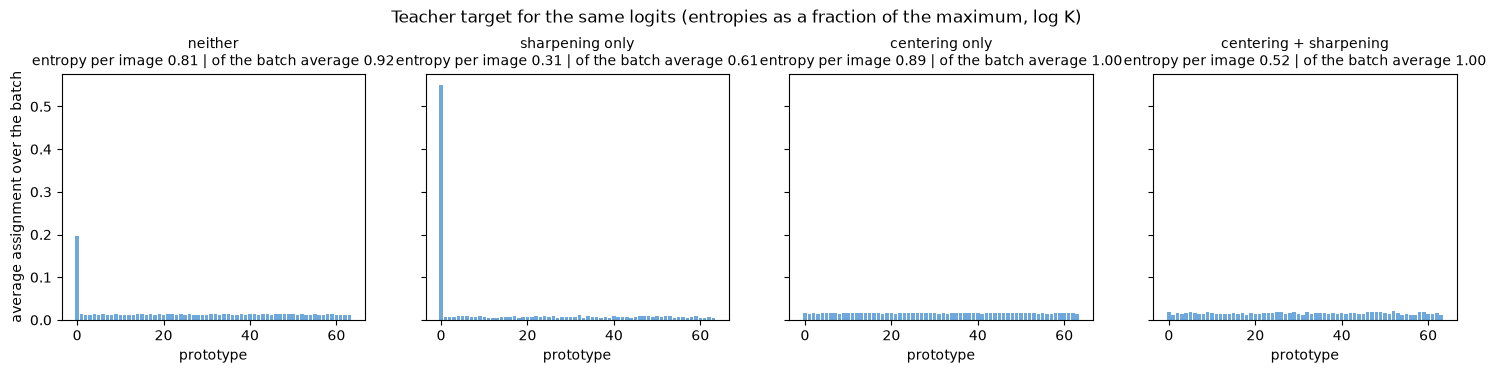

In [6]:
torch.manual_seed(0)
B, K = 512, 64
logits = 0.1 * torch.randn(B, K)          # individual preferences of the images
logits[:, 0] += 0.3                       # a bias shared by all images
center = logits.mean(dim=0, keepdim=True)


def entropy(p):
    return -(p * p.clamp_min(1e-12).log()).sum(dim=-1)


settings = {"neither": (0.0, 0.1), "sharpening only": (0.0, 0.04), "centering only": (1.0, 0.1), "centering + sharpening": (1.0, 0.04)}
fig, axes = plt.subplots(1, 4, figsize=(18, 3.2), sharey=True)
for ax, (label, (use_center, tau)) in zip(axes, settings.items()):
    p = F.softmax((logits - use_center * center) / tau, dim=-1)
    ax.bar(range(K), p.mean(dim=0), color="#6fa8dc")
    ax.set_title(f"{label}\nentropy per image {entropy(p).mean() / math.log(K):.2f} | of the batch average {entropy(p.mean(dim=0)) / math.log(K):.2f}",
                 fontsize=10)
    ax.set_xlabel("prototype")
axes[0].set_ylabel("average assignment over the batch")
plt.suptitle("Teacher target for the same logits (entropies as a fraction of the maximum, log K)", y=1.08)
plt.show()

What we want is a **low entropy per image** (a confident target) together with a **high entropy of the batch average** (all prototypes in use). Sharpening alone gives the first without the second — prototype 0 takes everything; centering alone gives the second without the first; only the combination gives both. These two entropies are exactly what we will monitor in the training runs.

## Multi-crop and the EMA teacher

**Multi-crop** (introduced in SwAV) creates two kinds of views of an image:

* 2 **global** crops: a large part of the image (here 40–100% of the area) at full resolution ($96 \times 96$);
* several **local** crops: a small part (5–40%) at low resolution ($48 \times 48$, i.e. $6 \times 6$ tokens).

The student processes all of them, the teacher only the global ones. The task becomes **local-to-global**: from a small piece of the object, predict what the teacher says about the whole. Local crops are cheap — a quarter of the tokens — so the number of positive pairs per image grows from 2 to 14 for a moderate cost. A ViT handles the second resolution without changes; only the positional embeddings are interpolated.

The **teacher** is updated after every step as $\theta_t \leftarrow \lambda\, \theta_t + (1 - \lambda)\, \theta_s$, with $\lambda$ going from 0.99 to 1 along a cosine (0.996 → 1 in the paper, which trains for many more steps). The paper observes that during the whole training the teacher is *better* than the student — it acts as an ensemble of the recent students (Polyak averaging) — and this is what makes distilling from it worthwhile.

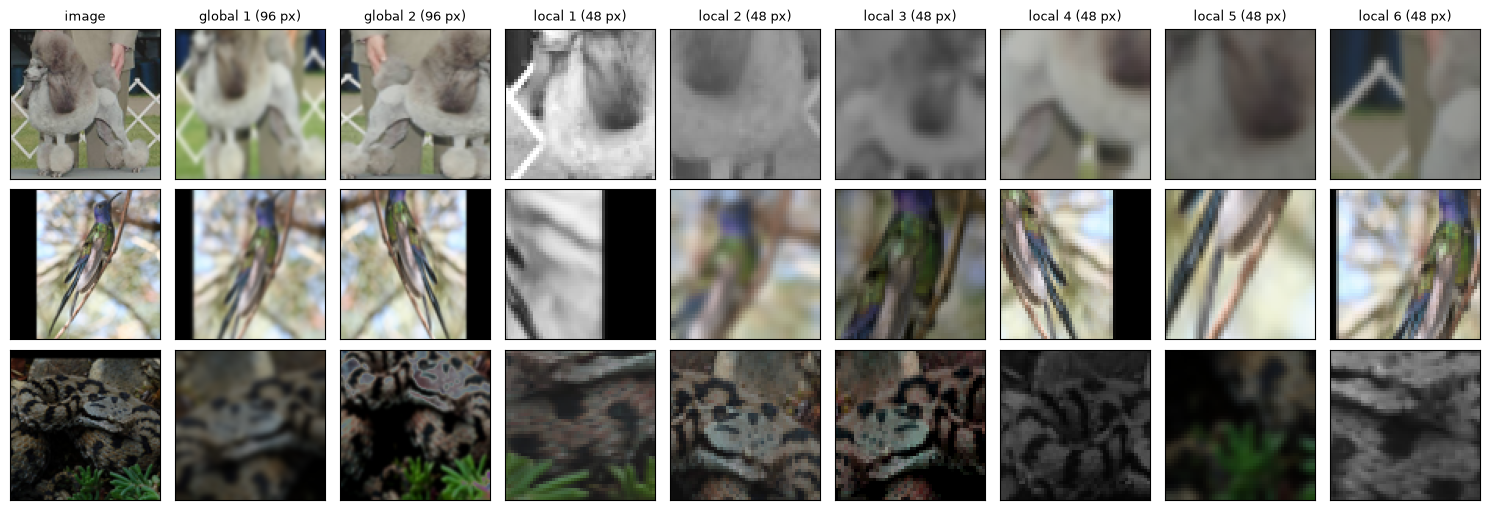

In [7]:
class MultiCrop(nn.Module):
    """DINO views: 2 global crops (large part of the image, full resolution) + n_local small low-resolution crops."""

    def __init__(self, n_local=6, img_size=96, local_size=48, global_scale=(0.4, 1.0), local_scale=(0.05, 0.4)):
        super().__init__()
        self.n_local = n_local
        self.global1 = BatchAugment(img_size, crop_scale=global_scale, blur_p=1.0)
        self.global2 = BatchAugment(img_size, crop_scale=global_scale, blur_p=0.1, solarize_p=0.2)
        self.local = BatchAugment(local_size, crop_scale=local_scale, blur_p=0.5)

    def forward(self, x):
        return [self.global1(x), self.global2(x)] + [self.local(x) for _ in range(self.n_local)]


unlabeled_x, _ = load_stl10(DATA_DIR, "unlabeled")
set_seed(0)
batch = torch.from_numpy(np.array(unlabeled_x[[11, 25, 42]])).to(DEVICE)
views = MultiCrop(n_local=6).to(DEVICE)(batch)

fig, axes = plt.subplots(3, 9, figsize=(15, 5.2))
for row, ax_row in enumerate(axes):
    ax_row[0].imshow(batch[row].permute(1, 2, 0).cpu())
    for col, view in enumerate(views):
        ax_row[col + 1].imshow(view[row].permute(1, 2, 0).cpu())
    for ax in ax_row:
        ax.set_xticks([]); ax.set_yticks([])
for ax, title in zip(axes[0], ["image", "global 1 (96 px)", "global 2 (96 px)"] + [f"local {i + 1} (48 px)" for i in range(6)]):
    ax.set_title(title, fontsize=9)
plt.tight_layout()
plt.show()

The whole method. `encoder` is the ViT; `encoder(x)[:, 0]` is its [CLS] token.

In [8]:
def cosine_momentum(base, progress):
    """EMA coefficient that goes from `base` to 1 along a cosine, progress in [0, 1]."""
    return 1 - (1 - base) * (math.cos(math.pi * progress) + 1) / 2


class DINO(nn.Module):
    def __init__(self, encoder, out_dim=4096, student_temp=0.1, teacher_temp=0.04, center_momentum=0.9, ema=0.99,
                 ema_schedule=True, centering=True):
        super().__init__()
        self.student, self.student_head = encoder, DINOHead(encoder.embed_dim, out_dim)
        self.teacher, self.teacher_head = frozen_copy(self.student), frozen_copy(self.student_head)
        self.student_temp, self.teacher_temp, self.center_momentum = student_temp, teacher_temp, center_momentum
        self.ema, self.ema_schedule, self.centering = ema, ema_schedule, centering
        self.register_buffer("center", torch.zeros(1, out_dim))
        self.stats = {}

    def forward(self, views, n_global=2):
        # teacher: global views only, no gradient
        with torch.no_grad():
            teacher_logits = self.teacher_head(self.teacher(torch.cat(views[:n_global]))[:, 0])
        # student: all views; one forward pass per resolution
        student_logits = self.student_head(self.student(torch.cat(views[:n_global]))[:, 0]).chunk(n_global)
        if len(views) > n_global:
            n_local = len(views) - n_global
            student_logits += self.student_head(self.student(torch.cat(views[n_global:]))[:, 0]).chunk(n_local)
        loss = dino_loss(student_logits, teacher_logits.chunk(n_global), self.center, self.student_temp, self.teacher_temp)

        with torch.no_grad():
            if self.centering:                                 # running mean of the teacher logits
                self.center.mul_(self.center_momentum).add_(teacher_logits.mean(dim=0, keepdim=True),
                                                            alpha=1 - self.center_momentum)
            # diagnostics (Fig. 7 of the paper): entropy of the teacher target and KL(teacher || student)
            p_t = F.softmax((teacher_logits.chunk(n_global)[0] - self.center) / self.teacher_temp, dim=-1)
            log_p_s = F.log_softmax(student_logits[1] / self.student_temp, dim=-1)
            entropy = -(p_t * p_t.clamp_min(1e-12).log()).sum(dim=-1).mean()
            self.stats = {"teacher_entropy": entropy.item(), "kl": (-(p_t * log_p_s).sum(dim=-1).mean() - entropy).item(),
                          "prototypes_used": p_t.argmax(dim=-1).unique().numel()}
        return loss

    def step_end(self, progress):
        tau = cosine_momentum(self.ema, progress) if self.ema_schedule else self.ema
        ema_update(self.teacher, self.student, tau)
        ema_update(self.teacher_head, self.student_head, tau)

    @torch.no_grad()
    def features(self, x):
        return {"teacher": self.teacher(x)[:, 0], "student": self.student(x)[:, 0]}

<a id='DINO_Experiments'></a>
# DINO: what prevents collapse, and what the teacher and multi-crop give

## Experiment: two ways to collapse

Four runs of 30 epochs: DINO, DINO without centering, without sharpening ($\tau_t = \tau_s = 0.1$), and without both. Following Figure 7 of the paper we log two quantities of the teacher's target during training:

* its **entropy** $H(P_t)$, averaged over the batch: $\log K = 8.3$ for a uniform target, 0 for a one-hot target;
* the **KL divergence** $D_{KL}(P_t \,\Vert\, P_s)$ between teacher and student for two different crops — the part of the loss that carries a learning signal ($H(P_t, P_s) = H(P_t) + D_{KL}(P_t \Vert P_s)$). If it is zero, the student has nothing to learn.

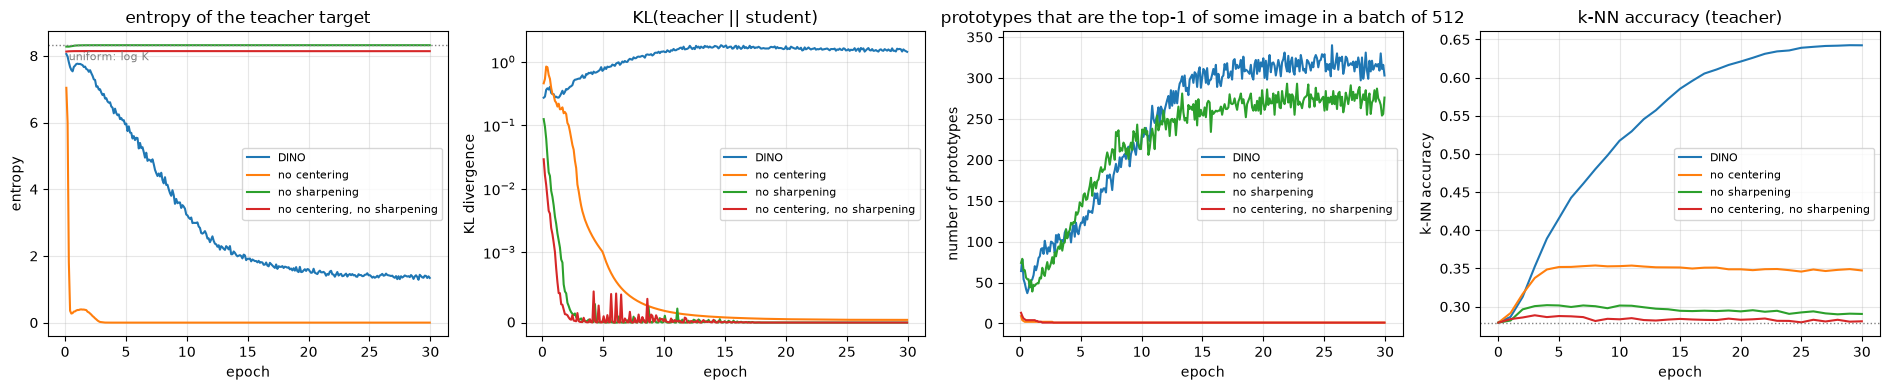

,knn_acc,linear_acc,rankme_h
DINO,64.2%,70.3%,68
no centering,34.7%,45.7%,14
no sharpening,29.0%,41.2%,2
"no centering, no sharpening",28.1%,39.1%,2


In [9]:
collapse_runs = {"abl_dino": "DINO", "dino_no_centering": "no centering", "dino_no_sharpening": "no sharpening",
                 "dino_no_centering_no_sharpening": "no centering, no sharpening"}
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
plot_runs(collapse_runs, "teacher_entropy", axes[0], steps=True, title="entropy of the teacher target", ylabel="entropy")
axes[0].axhline(math.log(4096), color="gray", ls=":", lw=1)
axes[0].text(0.3, math.log(4096) - 0.45, "uniform: log K", color="gray", fontsize=8)
plot_runs(collapse_runs, "kl", axes[1], steps=True, title="KL(teacher || student)", ylabel="KL divergence")
axes[1].set_yscale("symlog", linthresh=1e-3)
plot_runs(collapse_runs, "prototypes_used", axes[2], steps=True, title="prototypes that are the top-1 of some image in a batch of 512",
          ylabel="number of prototypes")
plot_runs(collapse_runs, "knn_acc", axes[3], title="k-NN accuracy (teacher)", ylabel="k-NN accuracy")
axes[3].axhline(RANDOM_INIT_KNN, color="gray", ls=":", lw=1)
plt.tight_layout()
plt.show()
results_table(collapse_runs)

### Takeaways (collapse in DINO)

* **Full DINO** is the only run that learns: the teacher entropy falls slowly from $\log K = 8.3$ to 1.4, the KL between teacher and student stays around 1.5 (the student always has something to catch up with), about 310 different prototypes are used in a batch of 512, and k-NN accuracy reaches 64.2%.
* **No centering → one prototype.** The entropy drops to 0 within the first three epochs, the loss goes to 0.000 and every image of the batch is assigned to the same prototype. This is the "one dimension dominates" collapse.
* **No sharpening → uniform.** With the teacher as soft as the student ($\tau_t = \tau_s = 0.1$) the entropy stays at $\log K$ and the loss at exactly 8.318 = $\log 4096$: the target carries no information. The "prototypes used" panel still shows ~270 for this run — the top-1 of an almost flat distribution is noise, so **this metric alone does not detect the uniform collapse; the entropy does**.
* **Neither** ends in the same flat state (entropy 8.14, KL 0, one top-1 prototype).
* In all three collapsed runs **KL goes to 0 while the loss stays constant** — the signature from the paper: the cross-entropy is all entropy and no divergence. The value of the loss tells you which collapse it is (0 or $\log K$).
* The collapsed encoders stay at 28–35% k-NN, i.e. at or slightly above the random-init ViT (27.9%): the small gain of "no centering" was made in the first epochs, before the collapse was complete. RankMe falls to 2–14 against 68 for DINO.

## Experiment: the teacher and multi-crop

Two more questions about the design:

* **Is the teacher really better than the student?** Every evaluation of the main 100-epoch run measures the k-NN accuracy of both networks.
* **What do the EMA and the local crops contribute?** Two ablations: a teacher that is a plain copy of the student ($\lambda = 0$; with the stop-gradient this is the SimSiam situation), and DINO with the two global crops only.

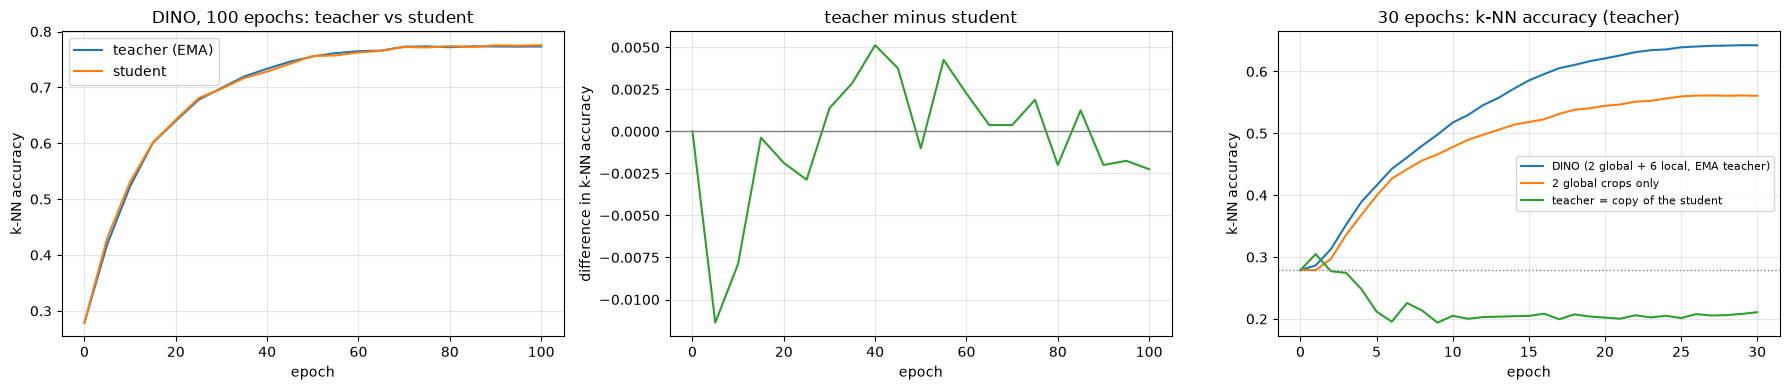

,knn_acc,knn_acc_student,linear_acc,rankme_h,minutes
"DINO (2 global + 6 local, EMA teacher)",64.2%,65.5%,70.3%,68,21
2 global crops only,56.1%,57.2%,62.6%,55,13
teacher = copy of the student,21.1%,21.1%,27.7%,1,21


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
d = load_run("dino").dropna(subset=["knn_acc"])
axes[0].plot(d.epoch, d.knn_acc, label="teacher (EMA)"); axes[0].plot(d.epoch, d.knn_acc_student, label="student")
axes[0].set_title("DINO, 100 epochs: teacher vs student"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("k-NN accuracy")
axes[0].grid(alpha=0.3); axes[0].legend()
axes[1].plot(d.epoch, d.knn_acc - d.knn_acc_student, color="tab:green")
axes[1].axhline(0, color="gray", lw=1); axes[1].set_title("teacher minus student"); axes[1].set_xlabel("epoch")
axes[1].set_ylabel("difference in k-NN accuracy"); axes[1].grid(alpha=0.3)
design_runs = {"abl_dino": "DINO (2 global + 6 local, EMA teacher)", "dino_no_multicrop": "2 global crops only",
               "dino_ema0": "teacher = copy of the student"}
plot_runs(design_runs, "knn_acc", axes[2], title="30 epochs: k-NN accuracy (teacher)", ylabel="k-NN accuracy")
axes[2].axhline(RANDOM_INIT_KNN, color="gray", ls=":", lw=1)
plt.tight_layout()
plt.show()
results_table(design_runs, columns=("knn_acc", "knn_acc_student", "linear_acc", "rankme_h", "minutes"))

### Takeaways (teacher and multi-crop)

* **The EMA teacher is necessary.** With the teacher equal to the current student (stop-gradient only) the run collapses in the first epochs: RankMe 1.2, k-NN 21.1% — *below* the random-init network. Centering and sharpening do not save it. This agrees with the paper, where a teacher copied at every step does not converge.
* **The teacher is not better than the student here.** The paper reports a teacher that is ahead of the student during the whole training. In our 100-epoch run the two are within ±0.5 pp after epoch 15 (final 77.3% vs 77.6%), and the student is ahead by ~1 pp in the first epochs. With $\lambda = 0.99$ and 195 steps per epoch the teacher averages over only about half an epoch, so it is almost the same network. Take either for the downstream task; the "ensemble" effect needs longer averaging and longer training.
* **Multi-crop: +8 pp of k-NN for 1.6× the time.** Removing the six local crops lowers k-NN from 64.2% to 56.1% and linear from 70.3% to 62.6% at 30 epochs, and the run takes 12.8 instead of 21.2 minutes. Per GPU-minute the two are closer than per epoch, but the multi-crop curve is still above after the same wall-clock time (61% against 56% at ~13 minutes).

<a id='Features'></a>
# What DINO features look like

The title of the DINO paper is *Emerging Properties in Self-Supervised Vision Transformers*, and its most famous figure is not a table. Take the **last block** of a DINO ViT and look at the attention of the [CLS] token to the patches: without any segmentation labels, the heads attend to the **object**, and different heads to different parts of it. The paper shows that a supervised ViT of the same size does not have this property.

Why would it emerge? A local crop shows a wing, the teacher saw the whole bird, and the student must output the teacher's distribution. The only way to do it is to recognise *which object* the piece belongs to, so the [CLS] token learns to collect the evidence from the object's patches and to ignore the background, which differs between crops.

First the original: the ViT-S/8 trained with DINO on ImageNet, loaded into **our** ViT from Lecture 1 (the weights fit because the module names follow `timm`). The STL-10 images are upsampled to $224 \times 224$, which gives a $28 \times 28$ attention map.

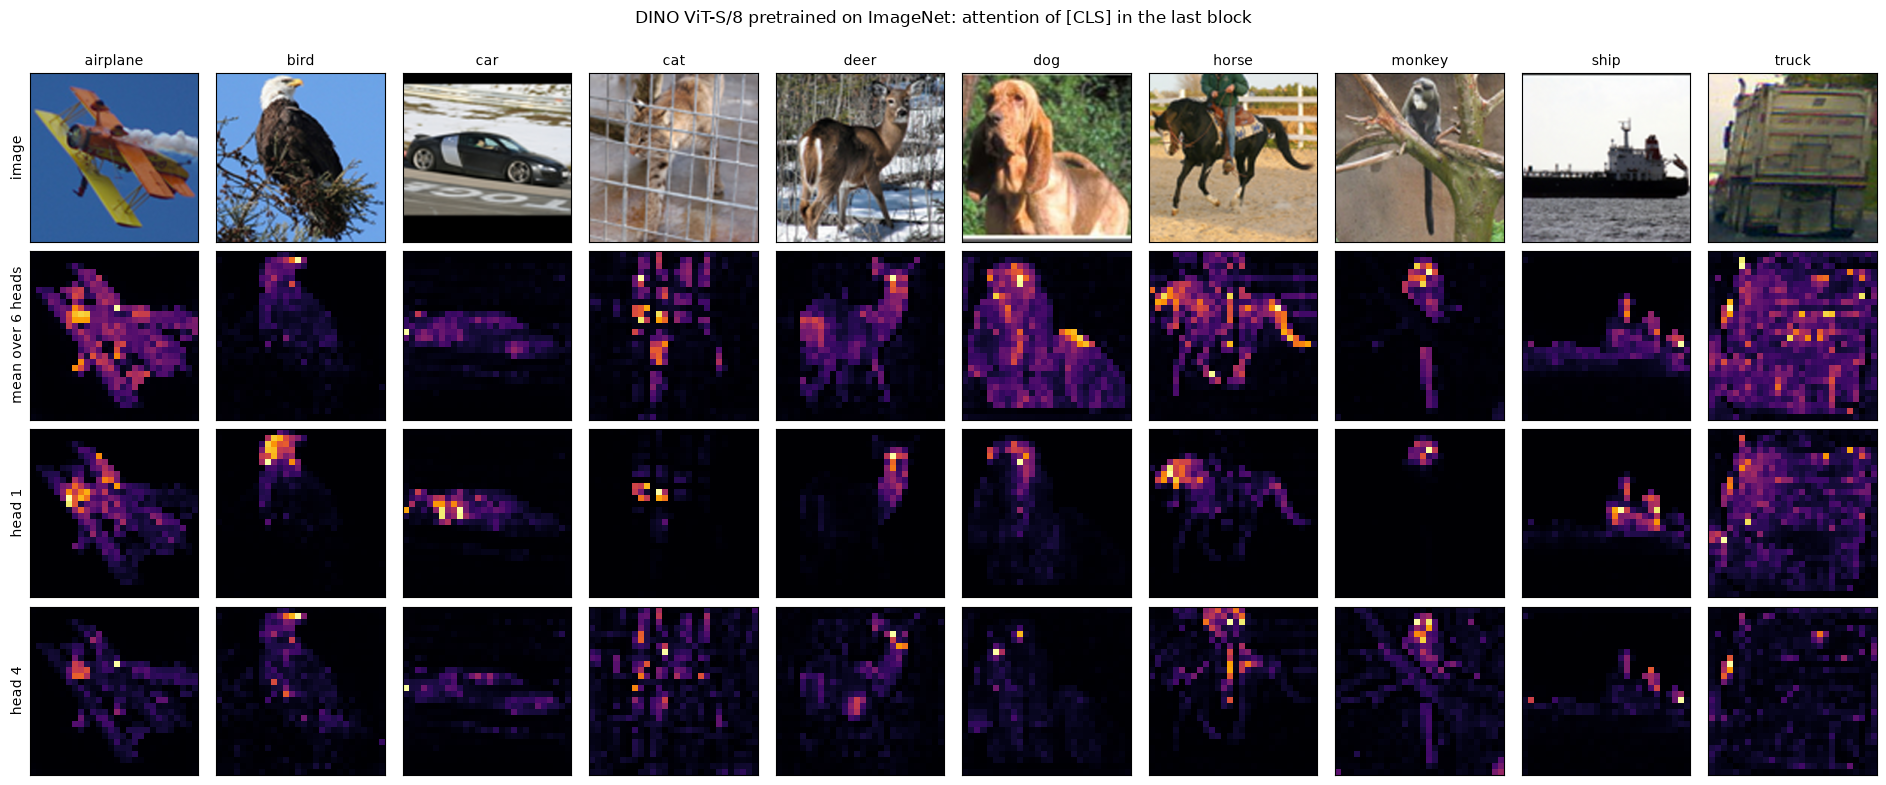

In [11]:
@torch.no_grad()
def cls_attention(model, x):
    """Attention of [CLS] to the patches in the last block. x: (B, 3, H, W) normalized. Returns (B, heads, h, w)."""
    model.eval()
    model.set_store_attn(True)
    model.forward_features(x)
    attn = model.get_attn_maps()[-1]                                  # (B, heads, 1 + N, 1 + N)
    model.set_store_attn(False)
    grid = int(math.sqrt(attn.shape[-1] - 1))
    return attn[:, :, 0, 1:].reshape(len(x), -1, grid, grid).float().cpu()


IMAGENET_MEAN, IMAGENET_STD = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1), torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
demo_idx = [int(np.nonzero(test_y == c)[0][0]) for c in range(10)]     # the first test image of every class
demo = torch.from_numpy(np.array(test_x[demo_idx])).float() / 255
demo_224 = F.interpolate(demo, size=224, mode="bicubic", align_corners=False).clamp(0, 1)

dino_s8 = VisionTransformer(img_size=224, patch_size=8, embed_dim=384, depth=12, num_heads=6, num_classes=0)
dino_s8.load_state_dict(timm.create_model("vit_small_patch8_224.dino", pretrained=True, num_classes=0).state_dict())
attn = cls_attention(dino_s8.to(DEVICE), ((demo_224 - IMAGENET_MEAN) / IMAGENET_STD).to(DEVICE))

fig, axes = plt.subplots(4, 10, figsize=(19, 7.8))
for i in range(10):
    axes[0, i].imshow(demo_224[i].permute(1, 2, 0)); axes[0, i].set_title(STL10_CLASSES[i], fontsize=10)
    axes[1, i].imshow(attn[i].mean(dim=0), cmap="inferno")
    axes[2, i].imshow(attn[i, 0], cmap="inferno"); axes[3, i].imshow(attn[i, 3], cmap="inferno")
for ax, label in zip(axes[:, 0], ["image", "mean over 6 heads", "head 1", "head 4"]):
    ax.set_ylabel(label, fontsize=10)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("DINO ViT-S/8 pretrained on ImageNet: attention of [CLS] in the last block", y=1.0)
plt.tight_layout()
plt.show()

Now **our own** ViT-Ti/8 models, trained on 100k small images for 100 epochs: DINO, MoCo v3 (the run of Lecture 4, the same backbone and data) and the supervised ViT trained on the 5k labels. `train.py` stored the attention maps of twelve test images (upsampled $2\times$, so the map is $24 \times 24$).

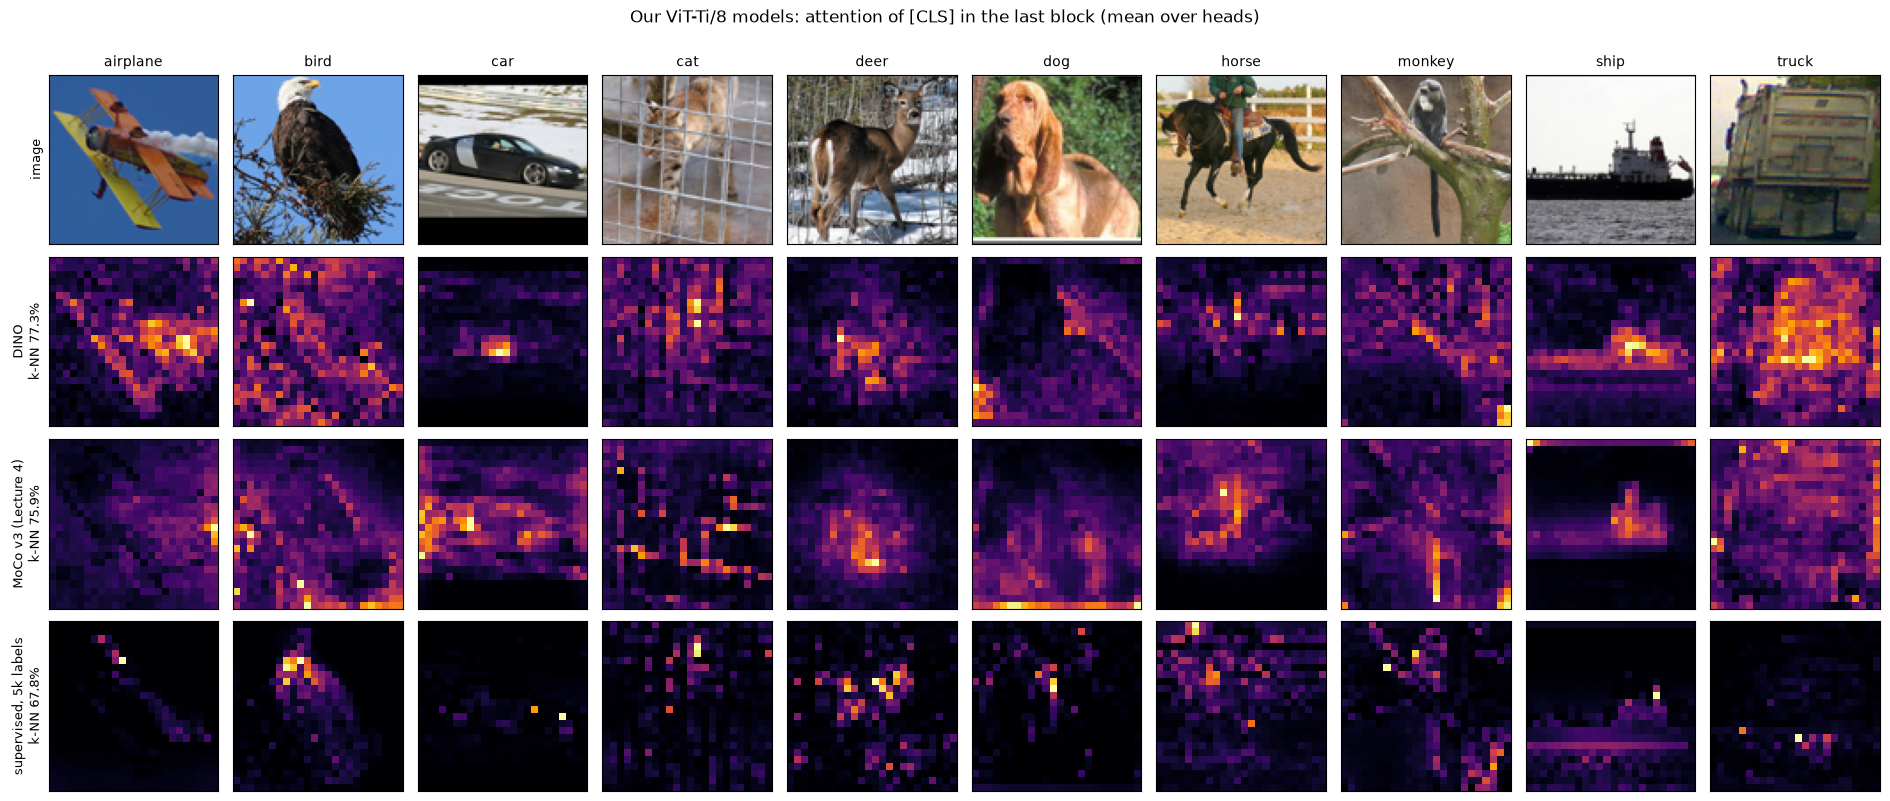

In [12]:
def load_artifact(name):
    return np.load(os.path.join(RESULTS_DIR, "artifacts", f"{name}.npz"))


attention_runs = {"dino": "DINO", "mocov3_vit_tiny": "MoCo v3 (Lecture 4)", "supervised_5k": "supervised, 5k labels"}
idx = load_artifact("dino")["index"][:10]
fig, axes = plt.subplots(1 + len(attention_runs), 10, figsize=(19, 2 * (1 + len(attention_runs))))
for i, image_idx in enumerate(idx):
    axes[0, i].imshow(test_x[image_idx].transpose(1, 2, 0)); axes[0, i].set_title(STL10_CLASSES[test_y[image_idx]], fontsize=10)
for row, (name, label) in enumerate(attention_runs.items(), start=1):
    maps = load_artifact(name)["cls_attention"].astype(np.float32).mean(axis=1)      # mean over the 3 heads
    for i in range(10):
        axes[row, i].imshow(maps[i], cmap="inferno")
    axes[row, 0].set_ylabel(f"{label}\nk-NN {summary.loc[name, 'knn_acc']:.1%}", fontsize=9)
axes[0, 0].set_ylabel("image", fontsize=9)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Our ViT-Ti/8 models: attention of [CLS] in the last block (mean over heads)", y=1.0)
plt.tight_layout()
plt.show()

### Takeaways (attention maps)

* **Pretrained DINO ViT-S/8** (ImageNet, 800 epochs): the [CLS] attention follows the object without any supervision — the result that made DINO famous.
* **Our ViT-Ti/8 after 100 epochs on 100k images** is far from that: the DINO maps find the object in the simple cases (car, ship, truck, airplane), and are diffuse or stuck on a corner patch in others (dog, monkey). The data and the training length matter as much as the method.
* **MoCo v3** on the same backbone gives maps of similar quality. At this scale we cannot claim that DINO's attention is more object-centric than that of a contrastive ViT.
* **Supervised** training on 5k labels attends to a handful of patches — enough to pick one of 10 classes, not a description of the object.
* The attention map of one block is a qualitative picture, not a metric; the patch-token PCA in the comparison section says more about what the features contain.

<a id='DINO_Family'></a>
# From DINO to DINOv3

DINO supervises one token — [CLS]. The next four years added supervision for the **patch tokens**, more data, and fixes for what breaks at scale.

| | Year | What is new | Result |
|---|---|---|---|
| **DINO** | 2021 | self-distillation of [CLS] over prototypes, centering + sharpening, multi-crop | ViT-S/16: 77.0% linear, 74.5% k-NN on ImageNet; object-centric attention |
| **iBOT** | 2021 | + **masked image modeling as self-distillation**: the student sees an image with masked patches and predicts the teacher's distribution for *every masked patch* (the teacher sees the full image). The teacher is an "online tokenizer" | better dense features and linear accuracy than DINO |
| **DINOv2** | 2023 | DINO loss on [CLS] + iBOT loss on patches, Sinkhorn–Knopp instead of centering, the KoLeo regularizer (spreads the features in a batch), a curated set of **142M images**, a ViT-g teacher distilled into smaller models | the first SSL features that work **frozen** across classification, segmentation and depth (ViT-g: 86.5% linear on ImageNet) |
| **Registers** | 2023 | large models repurpose a few background patches as global memory (high-norm outlier tokens that spoil the attention maps). Adding 4 extra **register tokens** gives that memory a proper place | clean attention maps and dense features |
| **DINOv3** | 2025 | **1.7B images**, a 7B-parameter ViT, RoPE positions, and **Gram anchoring**: during long training the patch features degrade while the global ones improve, so the patch-to-patch similarities are tied to those of an earlier teacher | state-of-the-art frozen dense features; a family of distilled ViTs and ConvNeXts |

Notice the pattern in the second row: iBOT's patch objective — *the student sees a part, the teacher sees everything, the target is in representation space* — is already very close to the second method of this lecture.

In Lecture 3 we measured these models with probes. Here is the qualitative picture behind the numbers: the **patch tokens** of four test images, projected onto their first three principal components and shown as RGB. The PCA is fitted on the patches of all four images together, so equal colours mean similar features *across* images.

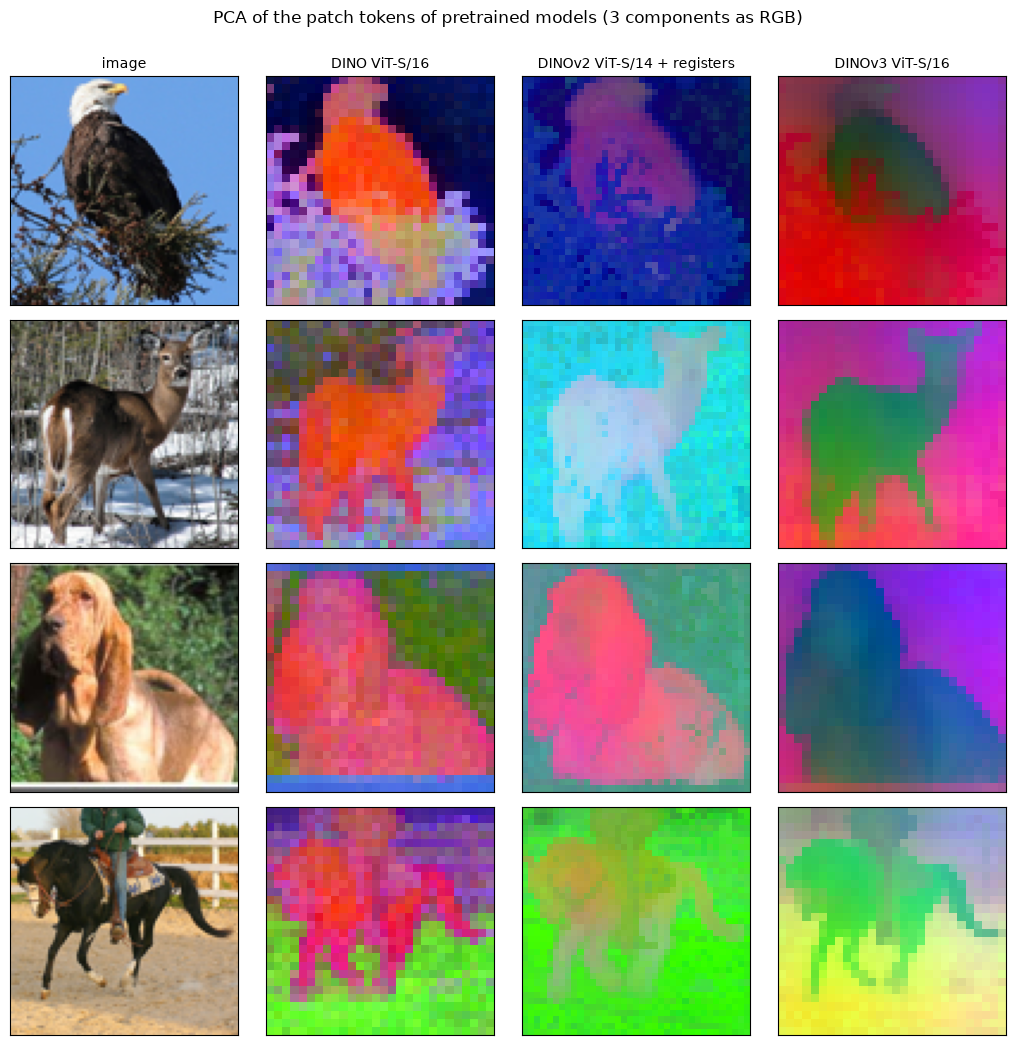

In [13]:
@torch.no_grad()
def patch_pca(tokens):
    """tokens: (B, N, D) patch tokens -> (B, h, w, 3) in [0, 1]: the first 3 principal components over all patches."""
    b, n, d = tokens.shape
    flat = tokens.reshape(-1, d).float()
    flat = flat - flat.mean(dim=0, keepdim=True)
    _, _, v = torch.pca_lowrank(flat, q=3, center=False)
    return to_rgb((flat @ v).reshape(b, int(math.sqrt(n)), int(math.sqrt(n)), 3).cpu().numpy())


def to_rgb(pca):
    """Rescale every component to [0, 1] (robustly, by its 1st and 99th percentiles)."""
    lo, hi = np.percentile(pca, 1, axis=(0, 1, 2)), np.percentile(pca, 99, axis=(0, 1, 2))
    return ((pca - lo) / (hi - lo)).clip(0, 1)


pretrained = {"DINO ViT-S/16": "vit_small_patch16_224.dino", "DINOv2 ViT-S/14 + registers": "vit_small_patch14_reg4_dinov2.lvd142m",
              "DINOv3 ViT-S/16": "vit_small_patch16_dinov3.lvd1689m"}
pca_idx = [demo_idx[i] for i in (1, 4, 5, 6)]                     # bird, deer, dog, horse
pca_images = torch.from_numpy(np.array(test_x[pca_idx])).float() / 255
fig, axes = plt.subplots(len(pca_images), 1 + len(pretrained), figsize=(2.6 * (1 + len(pretrained)), 2.6 * len(pca_images)))
for row, image in enumerate(pca_images):
    axes[row, 0].imshow(image.permute(1, 2, 0))
axes[0, 0].set_title("image", fontsize=10)
for col, (label, ckpt) in enumerate(pretrained.items(), start=1):
    size = 448 if "patch16" in ckpt else 518                      # a 28 x 28 or 37 x 37 grid of patches
    model = timm.create_model(ckpt, pretrained=True, num_classes=0, img_size=size).to(DEVICE).eval()
    x = F.interpolate(pca_images, size=size, mode="bicubic", align_corners=False).clamp(0, 1)
    with torch.no_grad():
        tokens = model.forward_features(((x - IMAGENET_MEAN) / IMAGENET_STD).to(DEVICE))[:, model.num_prefix_tokens:]
    for row, rgb in enumerate(patch_pca(tokens)):
        axes[row, col].imshow(rgb)
    axes[0, col].set_title(label, fontsize=10)
    del model
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("PCA of the patch tokens of pretrained models (3 components as RGB)", y=1.0)
plt.tight_layout()
plt.show()

With no labels of any kind, the first principal components separate the animal from the background, and similar parts tend to get similar colours across images. From DINO to DINOv3 the maps become sharper and less noisy — the effect of the patch-level objective, the registers and Gram anchoring. This is why a *linear* layer on frozen DINOv2/v3 patch tokens was enough for segmentation in Lecture 3.

<a id='DINOv3'></a>
## DINOv3 in detail: what changed and why

DINOv3 (Siméoni et al., 2025) asks one question: *what breaks when DINO-style training is scaled to billions of images, billions of parameters and very long schedules, and how do you fix it?* The objective is still DINO + iBOT; almost every change is about **scale** or about **keeping the patch features good**.

**1. Data: 1.7B curated images.** The authors start from ~17B public Instagram images and build the training set from three parts:

* **LVD-1689M**: hierarchical k-means on DINOv2 embeddings (5 levels: 200M → 8M → 800k → 100k → 25k clusters), then *balanced* sampling across the clusters. Without balancing, the most frequent web concepts dominate; with it, rare concepts get a fair share.
* **retrieval-based curation**: images similar to those of downstream seed datasets;
* **raw public datasets**: ImageNet-1k, ImageNet-22k, Mapillary.

In 10% of the iterations a batch comes entirely from ImageNet-1k (a *homogeneous* batch); otherwise all sources are mixed. In the paper's ablation, the mix of all three is the best or close to the best on every benchmark, while each source alone is weak on some of them.

**2. Architecture: a ViT-7B built for any resolution.**

| | DINOv2 (ViT-g) | DINOv3 (ViT-7B) |
|---|---|---|
| Parameters | 1.1B | 6.7B |
| Blocks × width × heads | 40 × 1536 × 24 | 40 × 4096 × 32 |
| Patch size | 14 | **16** |
| Positions | learned embeddings (interpolated) | **RoPE** |
| Registers | added later (Darcet et al.) | 4, from the start |
| DINO / iBOT prototypes | 128k / 128k | 256k / 96k |

**RoPE** (rotary position embeddings) encodes positions by rotating queries and keys, so attention depends on *relative* offsets. There is nothing to interpolate when the resolution changes. DINOv3 places the patch coordinates in a normalized box $[-1, 1]$, and during training it randomly rescales the box to $[-s, s]$ with $s \in [0.5, 2]$ (**RoPE-box jittering**). This makes the features robust to resolution, scale and aspect ratio. Recall that our ViT interpolates its learned positional embeddings for the 48 px local crops; RoPE removes that step.

**3. Training: no schedule.** DINOv2 used cosine decay of the learning rate, weight decay and teacher momentum, all tied to a fixed total length. DINOv3 keeps **all three constant** after a warmup. Training therefore has no planned end: the model can be trained for as long as it keeps improving (1M iterations, batch 4096, 2 global crops at 256 px + 8 local crops at 112 px). The loss is that of DINOv2:

$$
\mathcal{L}_{\text{pre}} = \mathcal{L}_{\text{DINO}} + \mathcal{L}_{\text{iBOT}} + 0.1\, \mathcal{L}_{\text{KoLeo}},
$$

with **Sinkhorn–Knopp** instead of our running-mean centering. Sinkhorn–Knopp normalizes the teacher's assignment matrix so that every prototype receives the same total mass in a batch. It is the same "no prototype wins everywhere" constraint as centering, enforced exactly per batch instead of through a running average. The global and local crops also get **separate final LayerNorms**, since their token statistics differ (small gains on k-NN, ADE20k and NYU depth).

**4. The problem: dense features degrade during long training.** Without a schedule, training can run for a long time, and that exposes a failure: **global** metrics (ImageNet k-NN, linear) keep improving, but **dense** ones (segmentation) peak early, around 200k iterations, and then decline. The patch-similarity maps become noisy, and the patch tokens grow more and more similar to the [CLS] token. The model "globalizes" its patches: every patch starts describing the whole image instead of its own location. The DINO loss on [CLS] keeps rewarding this, and the iBOT loss is not strong enough to stop it.

**5. The fix: Gram anchoring.** The **Gram matrix** of an image holds all pairwise cosine similarities between its patch features: with $X \in \mathbb{R}^{P \times d}$ the L2-normalized patch features, $G = X X^\top \in \mathbb{R}^{P \times P}$. Gram anchoring ties the student's Gram matrix to that of a **Gram teacher** — an earlier checkpoint, from the time when the patch features were still good:

$$
\mathcal{L}_{\text{Gram}} = \big\lVert X_S X_S^\top - X_G X_G^\top \big\rVert_F^2 .
$$

The key property: the loss constrains only the **similarity structure** between patches ("this patch is like that one, unlike that one"), not the features themselves. The features can keep moving and improving, as long as their mutual similarities stay as clean as they were. Details:

* it is added as a **refinement phase** after the 1M iterations of pre-training, and only on the global crops;
* the Gram teacher is updated to the current EMA teacher every 10k iterations; an early teacher (100k–200k iterations) works, a late one (1M) does not, because its patches have already degraded;
* **high-resolution Gram teacher**: the Gram teacher receives the image at **2× the resolution** and its patch features are downsampled 2× (bicubic) to the student's grid. Features computed at high resolution and then downsampled are smoother and more precise, so the student is anchored to better targets than it could produce at its own resolution (about +2 mIoU on ADE20k).

The effect is fast: dense metrics recover and exceed their earlier peak within the first iterations of refinement, and global metrics are not hurt.

**6. High-resolution adaptation.** Pre-training uses 256 px crops. A short final phase (10k iterations) trains on mixed resolutions — global crops of 512 and 768 px, local crops of 112–336 px — with Gram anchoring kept on. After it, the features stay sharp and stable at resolutions far above the training size.

**7. A family of smaller models by distillation.** Few people can run a 7B model, so the 7B is used as a frozen teacher for ViT-S (21M), S+ (29M), B (86M), L (0.3B) and H+ (0.84B), and for ConvNeXt T/S/B/L (29M–198M). The students use the same DINO/iBOT objectives with the 7B as the teacher instead of an EMA. Gram anchoring is not needed, because the teacher's patches are already good. In **multi-student distillation**, the teacher's forward pass is computed once per batch and shared across all GPUs, so each additional student costs only its own training. The students are much better than models of the same size trained from scratch.

**8. Beyond natural images and pixels.**

* **dino.txt**: text alignment in the **LiT** setting: the DINOv3 backbone is frozen, and a text encoder is trained contrastively from scratch, with two extra transformer layers on top of the vision side. The image embedding is the [CLS] token concatenated with the mean of the patch tokens, so that it holds global and local information. This is exactly the recipe we will use in Lecture 6.
* **Satellite model**: the same pipeline on SAT-493M (493M Maxar RGB images at 0.6 m resolution), with state-of-the-art results on canopy height estimation. The method is domain-agnostic: only the data change.

**9. Results with a frozen backbone.**

| | ImageNet linear | ADE20k linear (mIoU) | NYUv2 depth (RMSE ↓) |
|---|---|---|---|
| DINOv2 ViT-g/14 | 87.3 | 49.5 | 0.372 |
| SigLIP 2 ViT-g/16 | 89.1 | 42.7 | 0.494 |
| PE-core G/14 | 89.3 | 38.9 | 0.590 |
| **DINOv3 ViT-7B/16** | 88.4 | **55.9** | **0.309** |

On global classification DINOv3 is slightly behind the best image–text models, which are trained with captions for billions of images. On **dense** tasks it is far ahead: +6 mIoU over DINOv2 and +13 over SigLIP 2. With the backbone still frozen and a trained decoder on top, it reaches 63.0 mIoU on ADE20k and 66.1 mAP on COCO detection, state-of-the-art level.

**What to remember.**

* At scale, the **patch features are the weak point** of [CLS]-driven self-distillation: global and dense quality can move in opposite directions. Gram anchoring fixes this by constraining the *relations* between patches, not their values.
* Constant schedules make training open-ended, and that is how the degradation was discovered.
* RoPE + jittering + a short high-resolution phase give one backbone for every resolution.
* The 7B model is mainly a **teacher**: in practice we use its distilled ViTs and ConvNeXts.
* Compare with Lecture 6: image–text models are better at *naming* things (zero-shot); self-distilled models are better at *locating and delineating* them. Modern encoders, such as SigLIP 2 and dino.txt, try to combine the two.

<a id='JEPA'></a>
# I-JEPA: predicting representations of masked regions

Every method so far — SimCLR, BYOL, DINO — learns **invariance to hand-crafted augmentations**. That has a price: somebody has to know which augmentations are safe (colour jitter is harmful if colour is the label; crops assume one centred object), and the representation is biased towards whatever the augmentations leave untouched.

The alternative family is **generative / masked modeling**: hide a part of the input and reconstruct it. **MAE** reconstructs the pixels of masked patches and needs no augmentations at all. But most of what must be predicted in pixel space is irrelevant detail — the exact texture of the grass — and, as Lecture 3 showed, MAE features are poor without fine-tuning (19% k-NN on Pets).

A **Joint-Embedding Predictive Architecture** (JEPA; LeCun, 2022) combines the two: **predict the missing part, but in representation space**. The target encoder is free to drop unpredictable detail, so the model can spend its capacity on the predictable, semantic part.

|  | Target | Views | Learns |
|---|---|---|---|
| Joint-embedding (SimCLR, BYOL, DINO) | embedding of another augmented view | hand-crafted augmentations | invariance |
| Generative (MAE) | **pixels** of the masked patches | masking | reconstruction |
| **JEPA** (I-JEPA) | **representation** of the masked patches | masking | prediction in latent space |

**I-JEPA** (Assran et al., 2023) is the image version:

* a **context encoder** (a ViT) processes only the visible patches of an image — one large *context block*;
* a **target encoder** — the EMA of the context encoder — processes the **whole** image; its output tokens at the positions of several **target blocks** are the targets;
* a **predictor** — a narrow ViT — receives the context tokens plus one *mask token* per target patch carrying the positional embedding of that patch, and outputs the predicted representation of every target patch;
* the loss is the distance between predicted and target tokens, with a stop-gradient on the target.

There is one view, no colour jitter, no multi-crop and no negatives; the only augmentation is a random crop. Collapse (a constant target is trivially predictable) is avoided by the same asymmetry as in BYOL: a predictor on one side, an EMA network with a stop-gradient on the other.

**The masking strategy is the "augmentation" of I-JEPA**, and the paper's main design finding. The targets must be **large blocks** (4 blocks, each 15–20% of the image): a block of that size contains an object part, so predicting its representation requires semantics, while scattered single patches can be interpolated from their neighbours. The context must be **informative** (85–100% of the image) and must not overlap the targets.

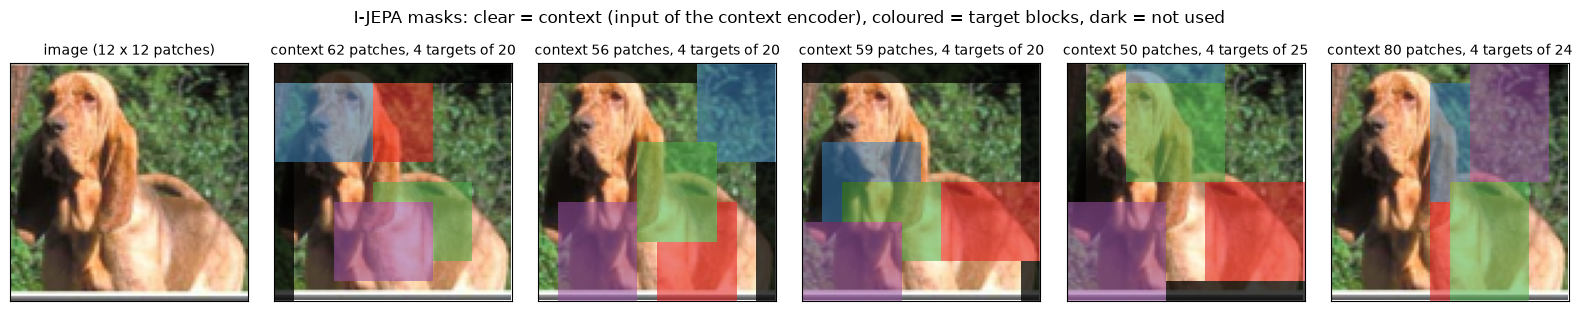

In [14]:
def sample_block_size(grid, scale, aspect, generator=None):
    """Height and width (in patches) of a block that covers `scale` of the grid with the given aspect ratio range."""
    u = torch.rand(2, generator=generator).tolist()
    area = (scale[0] + u[0] * (scale[1] - scale[0])) * grid * grid
    ratio = aspect[0] + u[1] * (aspect[1] - aspect[0])
    h, w = round(math.sqrt(area * ratio)), round(math.sqrt(area / ratio))
    return min(max(h, 1), grid), min(max(w, 1), grid)


def block_indices(grid, h, w, generator=None):
    """Flat indices of the patches of an h x w block at a random position of the grid."""
    top = torch.randint(0, grid - h + 1, (1,), generator=generator).item()
    left = torch.randint(0, grid - w + 1, (1,), generator=generator).item()
    rows, cols = torch.meshgrid(torch.arange(top, top + h), torch.arange(left, left + w), indexing="ij")
    return (rows * grid + cols).flatten()


def sample_ijepa_masks(grid=12, n_targets=4, target_scale=(0.15, 0.2), target_aspect=(0.75, 1.5),
                       context_scale=(0.85, 1.0), min_context=12, generator=None):
    """Multi-block masking of I-JEPA.

    Returns context (n_ctx,): the visible patches, and targets (n_targets, h * w): the blocks to predict.
    All target blocks have the same size and may overlap; the context is one large block minus all targets.
    """
    while True:
        h, w = sample_block_size(grid, target_scale, target_aspect, generator)
        targets = torch.stack([block_indices(grid, h, w, generator) for _ in range(n_targets)])
        ch, cw = sample_block_size(grid, context_scale, (1.0, 1.0), generator)
        context = block_indices(grid, ch, cw, generator)
        context = context[~torch.isin(context, targets.flatten())]
        if len(context) >= min_context:
            return context, targets


torch.manual_seed(3)
image = test_x[demo_idx[5]].transpose(1, 2, 0)
fig, axes = plt.subplots(1, 6, figsize=(16, 3))
axes[0].imshow(image); axes[0].set_title("image (12 x 12 patches)", fontsize=10)
for ax in axes[1:]:
    context, targets = sample_ijepa_masks()
    overlay = np.zeros((144, 4))
    overlay[:, 3] = 0.75                                               # hidden from the context encoder: dark
    overlay[context] = 0                                               # context: visible
    for block, color in zip(targets, plt.cm.Set1.colors):
        overlay[block] = (*color, 0.55)
    ax.imshow(image); ax.imshow(overlay.reshape(12, 12, 4), extent=(0, 96, 96, 0), interpolation="nearest")
    ax.set_title(f"context {len(context)} patches, 4 targets of {targets.shape[1]}", fontsize=10)
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("I-JEPA masks: clear = context (input of the context encoder), coloured = target blocks, dark = not used", y=1.02)
plt.tight_layout()
plt.show()

The predictor and the method. To keep the code short we sample **one set of masks per batch** (the official implementation samples them per image), and the four target blocks are predicted in parallel as four sequences.

In [15]:
class Predictor(nn.Module):
    """A narrow ViT that predicts the representation of the target patches from the context tokens.

    The targets enter as a shared learnable mask token plus the positional embedding of the patch to predict:
    the predictor is told *where* to predict, the context tells it *what* is in the image.
    """

    def __init__(self, num_patches, embed_dim=192, out_dim=192, pred_dim=96, depth=4, num_heads=3):
        super().__init__()
        self.embed = nn.Linear(embed_dim, pred_dim)
        self.mask_token = nn.Parameter(torch.zeros(1, 1, pred_dim))
        self.register_buffer("pos_embed", get_2d_sincos_pos_embed(pred_dim, int(math.sqrt(num_patches))), persistent=False)
        self.blocks = nn.Sequential(*[Block(pred_dim, num_heads) for _ in range(depth)])
        self.norm = nn.LayerNorm(pred_dim, eps=1e-6)
        self.proj = nn.Linear(pred_dim, out_dim)
        nn.init.trunc_normal_(self.mask_token, std=0.02)
        self.apply(VisionTransformer._init_weights)

    def forward(self, context_tokens, context, targets):
        """context_tokens: (B, n_ctx, D); context: (n_ctx,); targets: (T, n). Returns (B * T, n, out_dim)."""
        b, (t, n) = context_tokens.shape[0], targets.shape
        with torch.autocast(context_tokens.device.type, dtype=torch.bfloat16, enabled=context_tokens.is_cuda):
            ctx = self.embed(context_tokens) + self.pos_embed[context]                 # (B, n_ctx, d)
            queries = self.mask_token + self.pos_embed[targets]                        # (T, n, d)
            x = torch.cat([ctx.repeat_interleave(t, dim=0), queries.repeat(b, 1, 1)], dim=1)    # one sequence per block
            x = self.proj(self.norm(self.blocks(x))[:, -n:])
        return x.float()


class IJEPA(nn.Module):
    def __init__(self, encoder, ema=0.996, ema_schedule=True, target="latent", mask="multiblock", pred_dim=96,
                 pred_depth=4):
        super().__init__()
        assert encoder.cls_token is None and target in ("latent", "pixels") and mask in ("multiblock", "random")
        self.student, self.teacher = encoder, frozen_copy(encoder)        # context encoder and target encoder
        self.grid = encoder.patch_embed.grid_size
        out_dim = encoder.embed_dim if target == "latent" else 3 * encoder.patch_size ** 2
        self.predictor = Predictor(self.grid ** 2, encoder.embed_dim, out_dim, pred_dim, pred_depth)
        self.ema, self.ema_schedule, self.target, self.mask = ema, ema_schedule, target, mask
        self.stats = {}

    def forward(self, views):
        x = views[0]                                                     # a single view: no second augmentation
        context, targets = sample_ijepa_masks(self.grid) if self.mask == "multiblock" else sample_random_masks(self.grid)
        context, targets = context.to(x.device), targets.to(x.device)    # the same masks for the whole batch
        with torch.no_grad():
            if self.target == "latent":                                  # the target encoder sees the whole image
                h = self.teacher(x)
                h = F.layer_norm(h, (h.shape[-1],))
            else:                                                        # ablation: normalized pixels, as in MAE
                h = patchify(x, self.student.patch_size)
                h = (h - h.mean(dim=-1, keepdim=True)) / (h.var(dim=-1, keepdim=True) + 1e-6).sqrt()
            target_tokens = h[:, targets].flatten(0, 1)                  # (B * T, n, D)
            self.stats = {"target_std": h.std(dim=0).mean().item(), "context_patches": len(context)}
        context_tokens = self.student(x, keep=context)                   # the context encoder sees only the context
        prediction = self.predictor(context_tokens, context, targets)
        return F.smooth_l1_loss(prediction, target_tokens)

    def step_end(self, progress):
        ema_update(self.teacher, self.student, cosine_momentum(self.ema, progress) if self.ema_schedule else self.ema)

    @torch.no_grad()
    def features(self, x):
        return {"teacher": self.teacher(x).mean(dim=1), "student": self.student(x).mean(dim=1)}

## Experiment: what matters in I-JEPA

Four runs of 30 epochs:

* **I-JEPA** as described;
* **no EMA**: the target encoder is a copy of the context encoder (stop-gradient only);
* **pixel targets**: the same architecture and masks, but the predictor outputs the (normalized) pixels of the target patches — an MAE-style objective. In the paper this drops the low-shot ImageNet accuracy from about 67% to 41%;
* **random masks**: the same number of target patches, scattered over the image instead of forming blocks. In the paper the multi-block strategy gives about 54%, the alternatives 15–20%.

The image representation of I-JEPA is the **average of the patch tokens** of the target encoder (there is no [CLS] token). Besides accuracy we log the standard deviation of the target tokens over the batch: if it goes to zero, all images get the same targets.

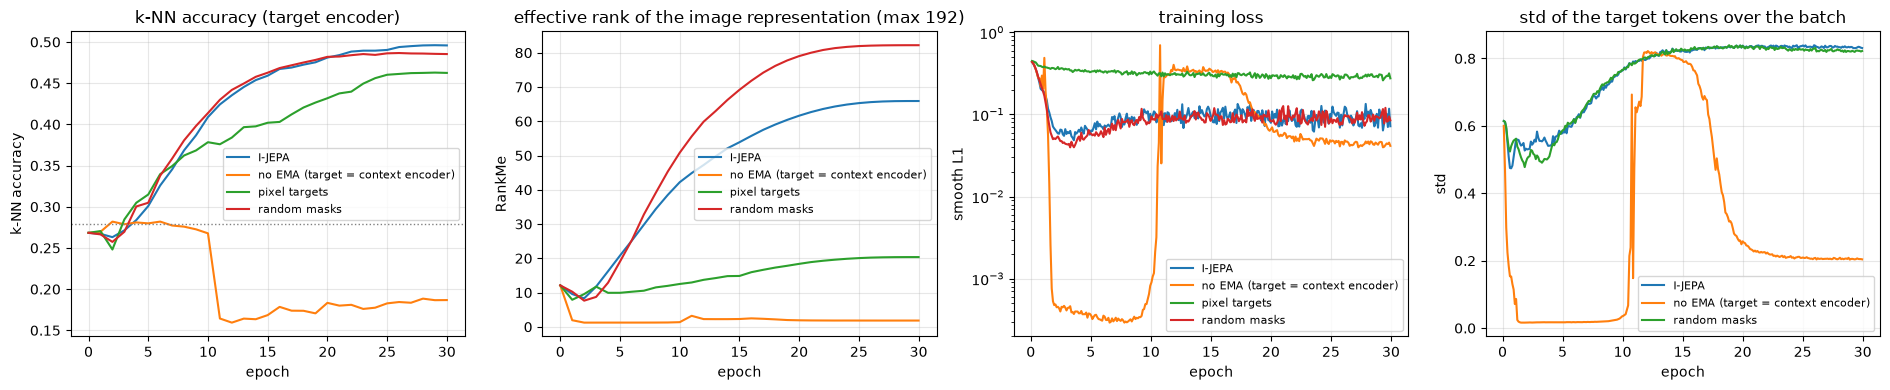

,knn_acc,knn_acc_student,linear_acc,rankme_h,minutes
I-JEPA,49.6%,50.2%,54.8%,66,6
no EMA (target = context encoder),18.7%,18.7%,27.8%,2,6
pixel targets,46.3%,49.0%,61.0%,20,5
random masks,48.5%,48.4%,56.8%,82,5


In [16]:
jepa_runs = {"abl_ijepa": "I-JEPA", "ijepa_ema0": "no EMA (target = context encoder)", "ijepa_pixels": "pixel targets",
             "ijepa_random_mask": "random masks"}
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
plot_runs(jepa_runs, "knn_acc", axes[0], title="k-NN accuracy (target encoder)", ylabel="k-NN accuracy")
axes[0].axhline(RANDOM_INIT_KNN, color="gray", ls=":", lw=1)
plot_runs(jepa_runs, "rankme_h", axes[1], title="effective rank of the image representation (max 192)", ylabel="RankMe")
plot_runs(jepa_runs, "loss", axes[2], steps=True, title="training loss", ylabel="smooth L1")
axes[2].set_yscale("log")
plot_runs({k: v for k, v in jepa_runs.items() if k != "ijepa_pixels"}, "target_std", axes[3], steps=True,
          title="std of the target tokens over the batch", ylabel="std")
plt.tight_layout()
plt.show()
results_table(jepa_runs, columns=("knn_acc", "knn_acc_student", "linear_acc", "rankme_h", "minutes"))

### Takeaways (I-JEPA)

* **No EMA → collapse**, as in DINO. With the target encoder equal to the context encoder the standard deviation of the targets falls to 0.02 within one epoch and the loss to 3·10⁻⁴: constant targets are trivially predictable. Around epoch 11 the run becomes unstable and settles at RankMe 1.8 and k-NN 18.7%, below the random-init network.
* **I-JEPA learns, but slowly**: 49.6% k-NN after 30 epochs (DINO: 64.2%), in 6.4 minutes instead of 21.2 — one view per image and a context encoder that sees ~65 of 144 patches. The loss is flat after the first epochs because the targets move together with the student; as in BYOL, **the loss is not a progress measure**, the target std and the rank are.
* **Pixel targets are not clearly worse here.** k-NN is lower (46.3% vs 49.6%) and the rank is much lower (20 vs 66), but the **linear probe is higher (61.0% vs 54.8%)**. The large drop reported in the paper is not reproduced.
* **Random masks are not worse either**: 48.5% / 56.8% against 49.6% / 54.8% for multi-block masks, with a higher rank (82). Note that our random masks also leave fewer context patches (43 vs 67), so the task is not easier.
* Why the difference with the paper: the paper's ablations use ViT-B/16 and larger on ImageNet at 224 px and measure low-shot classification. On 96 px images with a 12 × 12 grid a "block" is 4–6 patches wide, the model is 5M parameters, and 30 epochs are a few thousand steps. **We reproduce the mechanism of I-JEPA and its need for an EMA target, but not the two design claims.** Treat them as claims about the large-scale regime.

<a id='Comparison'></a>
# DINO and I-JEPA under the same budget

The two main runs — 100 epochs each on the 100k unlabeled images — next to two references with the **same ViT-Ti/8**: MoCo v3 from Lecture 4 (contrastive, the same data and number of epochs) and supervised training on the 5k labeled images. The pictures show the PCA of the patch tokens of our own models, computed as for the pretrained ones above.

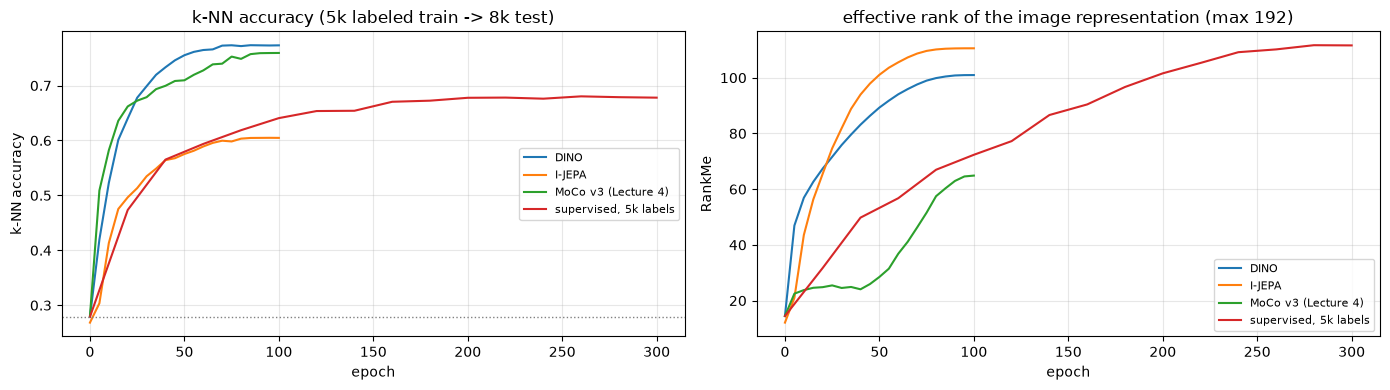

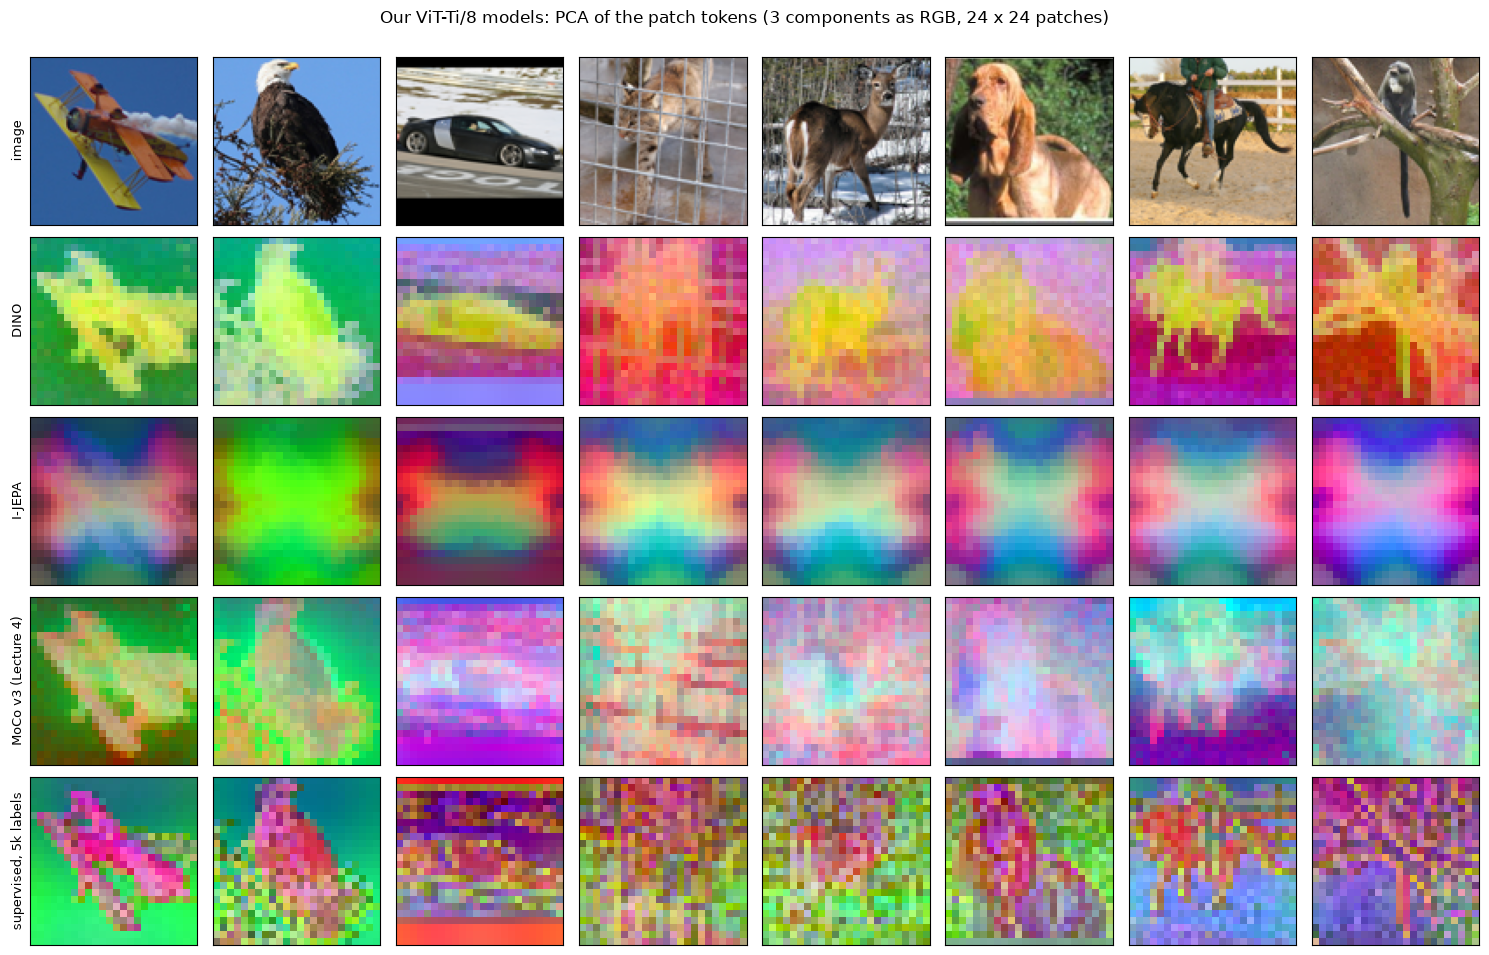

,knn_acc,linear_acc,rankme_h,minutes
DINO,77.3%,82.1%,101,67
I-JEPA,60.5%,65.8%,111,20
MoCo v3 (Lecture 4),75.9%,80.8%,65,39
"supervised, 5k labels",67.8%,68.3%,112,2


In [17]:
main_runs = {"dino": "DINO", "ijepa": "I-JEPA", "mocov3_vit_tiny": "MoCo v3 (Lecture 4)", "supervised_5k": "supervised, 5k labels"}
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_runs(main_runs, "knn_acc", axes[0], title="k-NN accuracy (5k labeled train -> 8k test)", ylabel="k-NN accuracy")
axes[0].axhline(RANDOM_INIT_KNN, color="gray", ls=":", lw=1)
plot_runs(main_runs, "rankme_h", axes[1], title="effective rank of the image representation (max 192)", ylabel="RankMe")
plt.tight_layout()
plt.show()

pca_runs = list(main_runs)
idx = load_artifact("dino")["index"][:8]
fig, axes = plt.subplots(1 + len(pca_runs), 8, figsize=(15, 1.9 * (1 + len(pca_runs))))
for i, image_idx in enumerate(idx):
    axes[0, i].imshow(test_x[image_idx].transpose(1, 2, 0))
for row, name in enumerate(pca_runs, start=1):
    rgb = to_rgb(load_artifact(name)["pca"].astype(np.float32)[:8])
    for i in range(8):
        axes[row, i].imshow(rgb[i])
    axes[row, 0].set_ylabel(main_runs[name], fontsize=9)
axes[0, 0].set_ylabel("image", fontsize=9)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Our ViT-Ti/8 models: PCA of the patch tokens (3 components as RGB, 24 x 24 patches)", y=1.0)
plt.tight_layout()
plt.show()
results_table(main_runs, columns=("knn_acc", "linear_acc", "rankme_h", "minutes"))

### Takeaways (comparison)

* **DINO is the best of the ViT-Ti/8 runs**: 77.3% k-NN / 82.1% linear, against 75.9% / 80.8% for MoCo v3 with the same data and epochs. The margin is 1.4 pp from single runs, so "at least as good" is the safe reading. DINO costs 67 minutes against 39 for MoCo v3 (multi-crop), and it is still below the ResNet-18 runs of Lecture 4 (83.6% k-NN).
* **I-JEPA is well behind**: 60.5% k-NN / 65.8% linear in 20 minutes — below the contrastive and DINO runs and, for k-NN, below the supervised ViT trained on only 5k labels (67.8% / 68.3%). Its curve is flat over the last 20 epochs, so the gap is not a matter of a few more epochs with this schedule. The paper's regime is ViT-H on ImageNet for hundreds of epochs; masked prediction is known to need large models and long schedules, and a short run on small images shows its weak side.
* **High rank is not the same as good features**: I-JEPA has the highest RankMe of the SSL runs (111) and the lowest accuracy; MoCo v3 has the lowest rank (65) and nearly the best accuracy. Rank detects collapse (Lecture 3), it does not order healthy runs across methods.
* **Patch tokens.** The DINO tokens separate the object from the background cleanly in most images, although DINO has no patch-level loss. MoCo v3 does so less clearly, and the supervised tokens are noisy. The **I-JEPA tokens show almost the same pattern in every image: they encode mostly the patch position**, not its content. This is consistent with the objective (the predictor is asked "what is at position $p$?") and with the weak accuracy: at this scale the encoder solved much of the task through position.
* What transfers to practice: under a small budget, augmentation-based self-distillation (or contrastive learning) is far more sample-efficient than masked latent prediction. The case for a JEPA is a domain without safe augmentations, or scale.

## Where the two lines go

**JEPA beyond images.** The argument for predicting in representation space is strongest where pixels are least predictable — video and action:

* **V-JEPA** (2024) applies the same recipe to video: mask space-time tubes, predict their representations. **V-JEPA 2** (2025) scales it to over a million hours of video and adds an action-conditioned predictor, which is used as a *world model* for robot planning.
* **LeJEPA** (2025) removes the EMA teacher, the stop-gradient and the schedules: collapse is prevented by one regularizer that makes the embeddings follow an isotropic Gaussian (compare with VICReg in Lecture 4).

**DINO as the default visual backbone.** DINOv2 / DINOv3 features are used frozen for segmentation, depth, retrieval and as the vision encoder of multimodal models. **SimDINO** (2025) shows that the collapse-avoidance machinery of DINO (centering, sharpening, the prototype head) can be replaced by an explicit coding-rate regularizer.

**When to use which (2025):**

* You need features and have no reason to train: take a pretrained **DINOv3 / DINOv2** — still the first thing to try (Lecture 3).
* You pre-train on your own domain with a ViT and can afford multi-crop: **DINO / DINOv2-style** self-distillation.
* Your domain has no safe augmentations (medical, satellite, spectrograms, sensor data), or you model video and actions: a **JEPA** — it needs only masking.

<a id='Summary'></a>
# Summary

* **Self-distillation**: a student is trained to match a teacher that is the **EMA of the student itself**. No labels, no negatives. The teacher is an ensemble of past students; in the paper it is ahead of the student during training, in our short runs the two are equal — but without the EMA both DINO and I-JEPA collapse.
* **DINO** distills a **distribution over learned prototypes** computed from the [CLS] token, with a cross-entropy loss and no predictor. Collapse has two forms — one prototype for everything, or a uniform distribution — and is prevented by two opposite operations on the teacher: **centering** and **sharpening**.
* **Multi-crop** makes the task local-to-global: the student sees small crops, the teacher only large ones. It gave +8 pp of k-NN accuracy in our ablation, and it is one reason why the [CLS] attention of a pretrained DINO ViT follows objects.
* **iBOT → DINOv2 → DINOv3** add a patch-level masked objective, curated data at scale, registers and Gram anchoring; the result is frozen features that work for both global and dense tasks.
* **I-JEPA** predicts the **representations** of large masked blocks from a context block: one view, no hand-crafted augmentations, a predictor and an EMA target encoder. The paper attributes the semantic features to predicting in latent space instead of pixel space and to masking **blocks** instead of scattered patches; our small-scale ablations do not reproduce either effect, and I-JEPA ends well below DINO (60.5% vs 77.3% k-NN).
* The questions of Lecture 4 still organise everything: *what are the views, what is predicted from what, and what stops the collapse?*

# Self-check questions

**Theory**
1. What is distilled in self-distillation, and where does the teacher come from? Why can the teacher be better than the student if it is built from the student's weights?
2. Describe the DINO head and loss. How does the loss differ from BYOL's, and which component of BYOL is missing?
3. Name the two forms of collapse in DINO. Which of them does centering prevent, which does sharpening prevent, and what happens with only one of the two?
4. Why are $H(P_t)$ and $D_{KL}(P_t \Vert P_s)$ useful to monitor? What do they look like in each form of collapse?
5. What is multi-crop? Which crops go to the teacher, and why does this encourage object-centric features?
6. What does iBOT add to DINO, and what do DINOv2 and DINOv3 add on top? What problem do register tokens solve?
7. Compare joint-embedding, generative and joint-embedding predictive architectures: what is the target in each?
8. Describe the three networks of I-JEPA and what each of them receives. What plays the role of the augmentations?
9. Why does I-JEPA predict large blocks rather than random patches, and representations rather than pixels?
10. When would you prefer a JEPA-style method over a DINO-style one?

**Practice**
1. Implement the DINO loss for 2 global and 6 local crops. How many (teacher, student) pairs contribute, and which are excluded?
2. Implement the centering update. What happens if you compute the centre from the student's outputs instead of the teacher's?
3. Your DINO run shows a teacher entropy equal to $\log K$ from the first epoch. Which hyperparameters do you change, and in which direction? What if the entropy is 0?
4. Extract the [CLS] attention maps of the last block from a pretrained ViT and turn them into a foreground mask. How would you evaluate it?
5. Implement multi-block mask sampling for a $14 \times 14$ grid so that all images of a batch keep the same number of context patches.
6. You pre-train on single-channel spectrograms where time and frequency axes have different meaning. Design the views for DINO and the masks for I-JEPA.